In [58]:
import rawpy
import sys
import os
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image, ExifTags
import numpy as np
import cv2
import imageio

### Deliverable 1-4

In [4]:
imageFolder = Path("images")
imagePaths = sorted(
    imageFolder.glob("cb*.DNG"),
    key=lambda imagePath: int(imagePath.stem[2:]),
)

boardSize = (9, 6)
objp = np.zeros((boardSize[0] * boardSize[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:boardSize[0], 0:boardSize[1]].T.reshape(-1, 2)

objpoints = []
imgpoints = []

for index, imagePath in enumerate(imagePaths):
    with rawpy.imread(str(imagePath)) as raw:
        rgb = raw.postprocess()

    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
    ret, corners = cv2.findChessboardCorners(bgr, boardSize, None)

    if ret:
        print(f"Chessboard corners found for {imagePath.name}.")
        cv2.drawChessboardCorners(bgr, boardSize, corners, ret)
        objpoints.append(objp.copy())

        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
        corners = cv2.cornerSubPix(
            gray,
            corners,
            (11, 11),
            (-1, -1),
            criteria=(
                cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
                30,
                0.001,
            ),
        )
        imgpoints.append(corners)
    else:
        print(f"Chessboard corners not found for {imagePath.name}.")

Chessboard corners found for cb1.DNG.
Chessboard corners found for cb2.DNG.
Chessboard corners found for cb3.DNG.
Chessboard corners found for cb4.DNG.
Chessboard corners found for cb5.DNG.
Chessboard corners found for cb6.DNG.
Chessboard corners found for cb7.DNG.
Chessboard corners found for cb8.DNG.
Chessboard corners found for cb9.DNG.
Chessboard corners found for cb10.DNG.
Chessboard corners found for cb11.DNG.
Chessboard corners found for cb12.DNG.
Chessboard corners found for cb13.DNG.
Chessboard corners found for cb14.DNG.
Chessboard corners found for cb15.DNG.


In [21]:
imageSize = (bgr.shape[1], bgr.shape[0])
ret, mtx, dist, rvecs, tvecs = cv2.calibrateCamera(
    objpoints,
    imgpoints,
    imageSize,
    None,
    None,
    flags=cv2.CALIB_FIX_K3,
)

mean_error = 0
for i in range(len(objpoints)):
    imgpoints2, _ = cv2.projectPoints(
        objpoints[i], rvecs[i], tvecs[i], mtx, dist
    )
    observed = imgpoints[i].reshape(-1, 2)
    projected = imgpoints2.reshape(-1, 2)
    error = cv2.norm(observed, projected, cv2.NORM_L2) / len(projected)
    mean_error += error

mean_error /= len(objpoints)
print(f"Total reprojection error: {mean_error}")

Total reprojection error: 0.5656550253823707


In [10]:
fx = float(mtx[0, 0])
fy = float(mtx[1, 1])
cx = float(mtx[0, 2])
cy = float(mtx[1, 2])
k1, k2, p1, p2, k3 = dist.ravel()[:5]

print(f"Calibrated focal lengths: fx = {fx:.3f} px, fy = {fy:.3f} px")
print(f"Principal point: cx = {cx:.3f} px, cy = {cy:.3f} px")
print(
    "Distortion coefficients: "
    f"k1 = {k1:.6g}, k2 = {k2:.6g}, p1 = {p1:.6g}, p2 = {p2:.6g}"
)
print(f"k3 assumed fixed at: {float(k3):.1f}")

import tifffile

with tifffile.TiffFile(imagePaths[0]) as dngFile:
    exifIfd = dngFile.pages[0].tags[34665].value
    focalLength = exifIfd["FocalLength"]
    focalLengthMm = float(focalLength[0]) / float(focalLength[1])

print(f"Lens focal length from DNG metadata: {focalLengthMm:.3f} mm")
print(
    "Note: converting calibrated fx/fy to mm requires sensor pixel pitch; "
    "the DNG does not provide it."
)

Calibrated focal lengths: fx = 3295.245 px, fy = 3229.030 px
Principal point: cx = 1564.943 px, cy = 1803.590 px
Distortion coefficients: k1 = -0.0594721, k2 = -0.0785006, p1 = 0.0133527, p2 = -0.0023516
k3 assumed fixed at: 0.0
Lens focal length from DNG metadata: 5.960 mm
Note: converting calibrated fx/fy to mm requires sensor pixel pitch; the DNG does not provide it.


#### D2

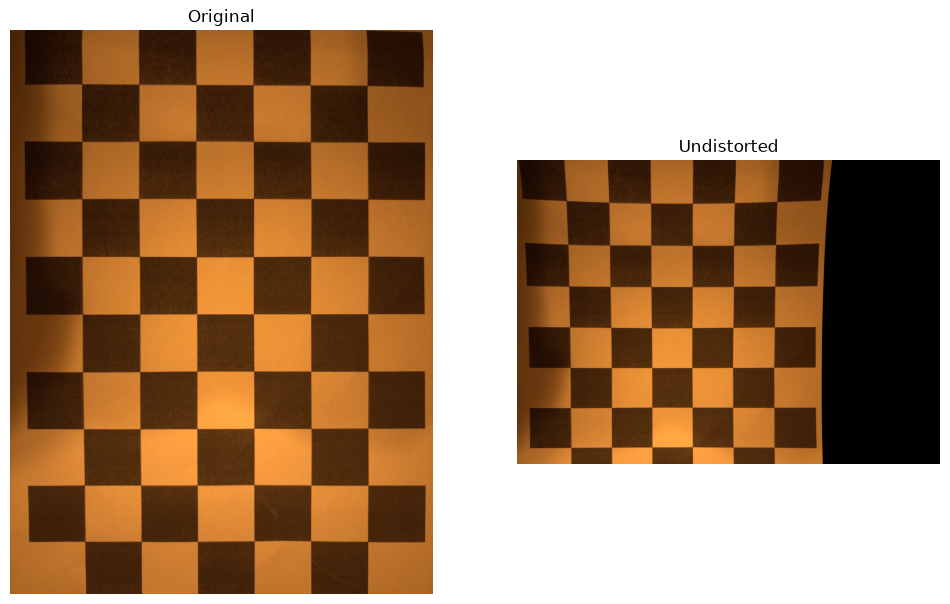

In [38]:
edge2Path = 'images/alt_edge.dng'

with rawpy.imread(str(edge2Path)) as raw:
    rgb = raw.postprocess()

image = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)

newCameraMatrix, roi = cv2.getOptimalNewCameraMatrix(
    mtx, dist, imageSize, alpha=1
)
# undistorted = cv2.undistort(image, mtx, dist, None, newCameraMatrix)
dst = cv2.undistort(image, mtx, dist, None, newCameraMatrix)
x, y, width, height = roi
dst = dst[y:y+ height, x:x + width]

plt.figure(figsize=(12, 10))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(dst, cv2.COLOR_BGR2RGB))
plt.title("Undistorted")
plt.axis("off")
plt.savefig('images/d2.png')
plt.show()

Selected original bottom edge line in alt_edge.dng; mean distance to edge = 374.5 px
Maximum deviation before undistortion: 3.124 px
Maximum deviation after undistortion:  3.730 px
Correction: -0.606 px (-19.4% reduction)


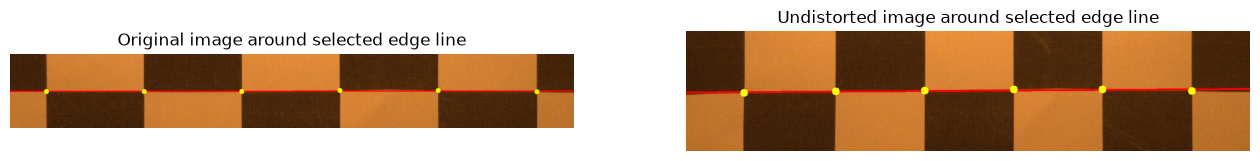

In [40]:
edge4Path = Path("images/alt_edge.dng")
with rawpy.imread(str(edge4Path)) as raw:
    edge4Rgb = raw.postprocess()

edge4Image = cv2.cvtColor(edge4Rgb, cv2.COLOR_RGB2BGR)
edge4ImageSize = (edge4Image.shape[1], edge4Image.shape[0])
if edge4ImageSize == imageSize:
    edgeCameraMatrix = mtx.copy()
    edgeDistortion = dist.ravel().copy()
elif edge4ImageSize == imageSize[::-1]:
    edgeCameraMatrix = np.array(
        [
            [mtx[1, 1], 0, mtx[1, 2]],
            [0, mtx[0, 0], edge4Image.shape[0] - 1 - mtx[0, 2]],
            [0, 0, 1],
        ],
        dtype=np.float64,
    )
    edgeDistortion = dist.ravel().copy()
    edgeDistortion[2:4] = (dist.ravel()[2], -dist.ravel()[3])
else:
    raise ValueError(
        f"Edge image size {edge4ImageSize} is incompatible with "
        f"calibration size {imageSize}."
    )

edge4Gray = cv2.cvtColor(edge4Image, cv2.COLOR_BGR2GRAY)
detectorFlags = (
    cv2.CALIB_CB_EXHAUSTIVE
    | cv2.CALIB_CB_ACCURACY
    | cv2.CALIB_CB_NORMALIZE_IMAGE
)
found = False
for detectedBoardSize in (boardSize, boardSize[::-1]):
    found, edge4Corners = cv2.findChessboardCornersSB(
        edge4Gray, detectedBoardSize, flags=detectorFlags
    )
    if found:
        break
if not found:
    raise ValueError(f"Checkerboard corners were not detected in {edge4Path.name}.")

edge4Corners = cv2.cornerSubPix(
    edge4Gray,
    edge4Corners,
    (11, 11),
    (-1, -1),
    criteria=(
        cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
        30,
        0.001,
    ),
).reshape(detectedBoardSize[1], detectedBoardSize[0], 2)

imageWidth, imageHeight = edge4ImageSize
edgeCandidates = []
for boundaryName, boundaryCorners in (
    ("top", edge4Corners[0, :, :]),
    ("bottom", edge4Corners[-1, :, :]),
    ("left", edge4Corners[:, 0, :]),
    ("right", edge4Corners[:, -1, :]),
):
    isInsideFrame = np.all(
        (boundaryCorners[:, 0] >= 0)
        & (boundaryCorners[:, 0] < imageWidth)
        & (boundaryCorners[:, 1] >= 0)
        & (boundaryCorners[:, 1] < imageHeight)
    )
    if not isInsideFrame:
        continue

    meanX = float(np.mean(boundaryCorners[:, 0]))
    meanY = float(np.mean(boundaryCorners[:, 1]))
    frameDistances = {
        "left": meanX,
        "right": imageWidth - 1 - meanX,
        "top": meanY,
        "bottom": imageHeight - 1 - meanY,
    }
    nearestSide = min(frameDistances, key=frameDistances.get)
    edgeCandidates.append(
        (frameDistances[nearestSide], nearestSide, boundaryCorners)
    )

if not edgeCandidates:
    raise ValueError("No complete checkerboard boundary is inside edge4.dng.")

edgeDistance, edgeName, edgeCorners = min(
    edgeCandidates, key=lambda candidate: candidate[0]
)
newCameraMatrix, _ = cv2.getOptimalNewCameraMatrix(
    edgeCameraMatrix, edgeDistortion, edge4ImageSize, alpha=1
)
correctedEdge4Image = cv2.undistort(
    edge4Image, edgeCameraMatrix, edgeDistortion, None, newCameraMatrix
)
correctedCorners = cv2.undistortPoints(
    edgeCorners.reshape(-1, 1, 2),
    edgeCameraMatrix,
    edgeDistortion,
    P=newCameraMatrix,
).reshape(-1, 2)

def fit_line_and_max_deviation(points):
    line = cv2.fitLine(
        points.astype(np.float32), cv2.DIST_L2, 0, 0.01, 0.01
    ).flatten()
    vx, vy, x0, y0 = line
    distances = np.abs(vy * (points[:, 0] - x0) - vx * (points[:, 1] - y0))
    return line, float(np.max(distances))

def draw_fitted_line(image, points, line):
    vx, vy, x0, y0 = line
    if abs(vx) > 1e-8:
        endpoints = []
        for xCoordinate in (0, image.shape[1] - 1):
            parameter = (xCoordinate - x0) / vx
            yCoordinate = y0 + parameter * vy
            endpoints.append((int(round(xCoordinate)), int(round(yCoordinate))))
    else:
        endpoints = [
            (int(round(x0)), 0),
            (int(round(x0)), image.shape[0] - 1),
        ]

    output = image.copy()
    cv2.line(output, endpoints[0], endpoints[1], (0, 0, 255), 3)
    for xCoordinate, yCoordinate in points:
        cv2.circle(
            output,
            (int(round(xCoordinate)), int(round(yCoordinate))),
            10,
            (0, 255, 255),
            -1,
        )
    return output

def crop_line_view(image, points, padding=150):
    cropLeft = max(0, int(np.floor(np.min(points[:, 0]) - padding)))
    cropTop = max(0, int(np.floor(np.min(points[:, 1]) - padding)))
    cropRight = min(image.shape[1], int(np.ceil(np.max(points[:, 0]) + padding + 1)))
    cropBottom = min(image.shape[0], int(np.ceil(np.max(points[:, 1]) + padding + 1)))
    croppedImage = image[cropTop:cropBottom, cropLeft:cropRight]
    croppedPoints = points - np.array([cropLeft, cropTop])
    croppedLine, _ = fit_line_and_max_deviation(croppedPoints)
    return draw_fitted_line(croppedImage, croppedPoints, croppedLine)

beforeLine, beforeDeviation = fit_line_and_max_deviation(edgeCorners)
afterLine, afterDeviation = fit_line_and_max_deviation(correctedCorners)
deviationReduction = beforeDeviation - afterDeviation
reductionPercent = 100 * deviationReduction / beforeDeviation

beforePlot = crop_line_view(edge4Image, edgeCorners)
afterPlot = crop_line_view(correctedEdge4Image, correctedCorners)
print(
    f"Selected original {edgeName} edge line in {edge4Path.name}; "
    f"mean distance to edge = {edgeDistance:.1f} px"
)
print(f"Maximum deviation before undistortion: {beforeDeviation:.3f} px")
print(f"Maximum deviation after undistortion:  {afterDeviation:.3f} px")
print(
    f"Correction: {deviationReduction:.3f} px "
    f"({reductionPercent:.1f}% reduction)"
)

plt.figure(figsize=(16, 7))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(beforePlot, cv2.COLOR_BGR2RGB))
plt.title("Original image around selected edge line")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(afterPlot, cv2.COLOR_BGR2RGB))
plt.title("Undistorted image around selected edge line")
plt.axis("off")
plt.savefig('images/d3.png')
plt.show()

In [ ]:
from pathlib import Path

import numpy as np
import rawpy
import tifffile

metadataImagePath = Path("images/cb1.DNG")

with tifffile.TiffFile(metadataImagePath) as dngFile:
    # EXIF FocalLength: actual lens focal length, recorded as a rational number.
    # For this DNG, this is approximately 5.96 mm.
    exifIfd = dngFile.pages[0].tags[34665].value
    actualFocalLengthMm = (
        float(exifIfd["FocalLength"][0]) / float(exifIfd["FocalLength"][1])
    )
    fNumber = exifIfd["FNumber"]
    fNumberValue = float(fNumber[0]) / float(fNumber[1])

    # EXIF FocalLengthIn35mmFilm: 35 mm-equivalent focal length.
    # For this DNG, the value is 26 mm.
    equivalentFocalLengthMm = float(exifIfd["FocalLengthIn35mmFilm"])

# Crop factor is the equivalent focal length divided by the actual focal length.
cropFactor = equivalentFocalLengthMm / actualFocalLengthMm

# 43.3 mm is the diagonal of a 36 mm x 24 mm 35 mm film frame.
filmDiagonalMm = 43.3
sensorDiagonalMm = filmDiagonalMm / cropFactor

# Get this DNG's processed image dimensions; orientation doesn't change its diagonal.
with rawpy.imread(str(metadataImagePath)) as raw:
    processedImage = raw.postprocess()

imageHeightPx, imageWidthPx = processedImage.shape[:2]
imageDiagonalPx = np.hypot(imageWidthPx, imageHeightPx)

# Convert mm per pixel to micrometers per pixel.
pixelPitchUm = 1000 * sensorDiagonalMm / imageDiagonalPx

print(f"Actual focal length from EXIF: {actualFocalLengthMm:.3f} mm")
print(f"EXIF f-number: f/{fNumberValue:.2f}")
print(f"35 mm-equivalent focal length from EXIF: {equivalentFocalLengthMm:.1f} mm")
print(f"Estimated crop factor: {cropFactor:.3f}")
print(f"Estimated sensor diagonal: {sensorDiagonalMm:.3f} mm")
print(f"Processed image dimensions: {imageWidthPx} x {imageHeightPx} px")
print(f"Image diagonal: {imageDiagonalPx:.1f} px")
print(f"Estimated pixel pitch: {pixelPitchUm:.3f} mm/px")

Actual focal length from EXIF: 5.960 mm
EXIF f-number: f/1.60
35 mm-equivalent focal length from EXIF: 26.0 mm
Estimated crop factor: 4.362
Estimated sensor diagonal: 9.926 mm
Processed image dimensions: 3024 x 4032 px
Image diagonal: 5040.0 px
Estimated pixel pitch: 1.969 um/px


In [47]:
(1.8270-1.969)/1.8270

-0.07772304324028469

### Deliverable 5-8

In [50]:
h = 0.55 #lambda um
N = 1.6
p = 1.8270 #um/px 

v_c = np.divide(1,h*N) #
print(f'vc in 1/um: {v_c:3.3f}')
print(f'vc in 1/mm: {v_c*1000:3.3f}')

## Green plan nyquist frequency

N_f = np.divide(1,4*p) # Nyquist frequency in 1/um
print(f'N_f in px/um: {N_f:3.3f}')
print(f'N_f in px/mm: {N_f*1000:3.3f}')

## Ratio of the two 

ratio = v_c/N_f
print(f'Ratio of vc to N_f: {ratio:3.3f}')
print(f'Ratio of vc to N_f in 1/um: {ratio/1000:3.3f}')

vc in 1/um: 1.136
vc in 1/mm: 1136.364
N_f in px/um: 0.137
N_f in px/mm: 136.836
Ratio of vc to N_f: 8.305
Ratio of vc to N_f in 1/um: 0.008


In [73]:
#Diffraction is the issue between the two as it is smaller

N_fFull = np.divide(1,2*p)
N_new = np.divide(1,h*N_fFull)
print(N_new)

0.007160000000000001


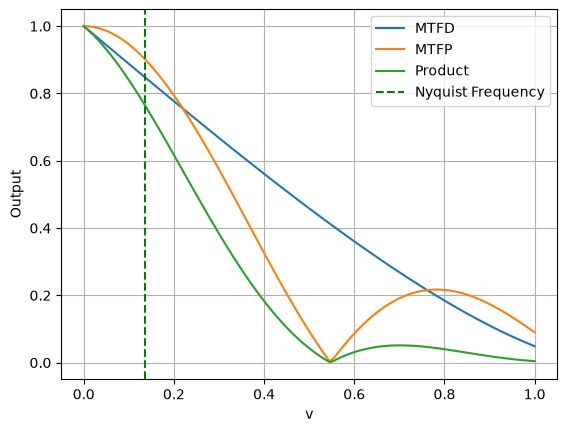

Value at Nyquist frequency: 0.7626155816628025


In [55]:
def mtfd(v, v_c):
    s = v/v_c
    bot = np.arccos(s) - s*np.sqrt(1-s**2)
    return( np.divide(2, np.pi)*bot)

def mtfp(v,p):
    return(abs(np.sinc(v*p)) )

p = 1.827 #um/px 

v = np.array([0, 0.1, 0.2])
v_c = np.divide(1,h*N) #
nF = np.divide(1,4*p) # Nyquist frequency in 1/um


v = np.linspace(0,1,100)

plt.plot(v, mtfd(v, v_c), label='MTFD')
plt.plot(v, mtfp(v, p), label='MTFP')
plt.plot(v, mtfd(v, v_c)*mtfp(v, p), label='Product')
plt.xlabel('v')
plt.ylabel('Output')

#veritcal line 
plt.axvline(x=nF, color='g', linestyle='--', label='Nyquist Frequency')
plt.grid()
plt.legend()
plt.savefig('images/d7.png')
plt.show()

print(f'Value at Nyquist frequency: {mtfd(nF, v_c)*mtfp(nF, p)}')

In [88]:
lowerFrequency = 0.0
upperFrequency = min(v_c, 1.0 / p)
for _ in range(60):
    midpointFrequency = (lowerFrequency + upperFrequency) / 2
    response = mtfd(midpointFrequency, v_c) * mtfp(midpointFrequency, p)
    if response > 0.5:
        lowerFrequency = midpointFrequency
    else:
        upperFrequency = midpointFrequency

mtf50 = (lowerFrequency + upperFrequency) / 2
print(f"Predicted MTF50: {mtf50:.4f} cycles/um")
print(f"Green-plane Nyquist: {nF:.4f} cycles/um")
print(f"MTF50 is above green-plane Nyquist: {mtf50 > nF}")

Predicted MTF50: 0.2368 cycles/um
Green-plane Nyquist: 0.1270 cycles/um
MTF50 is above green-plane Nyquist: True


The predicted MTF50 is 0.2368 cycles/um, above the green-plane Nyquist frequency of 0.1270 cycles/um. Detail above Nyquist cannot be uniquely represented and may alias into lower frequencies. Therefore, the Part 4 single-green-plane measurement cannot directly resolve this predicted optical MTF50; sampling and aliasing limit its interpretation.

### Deliberable 9-11

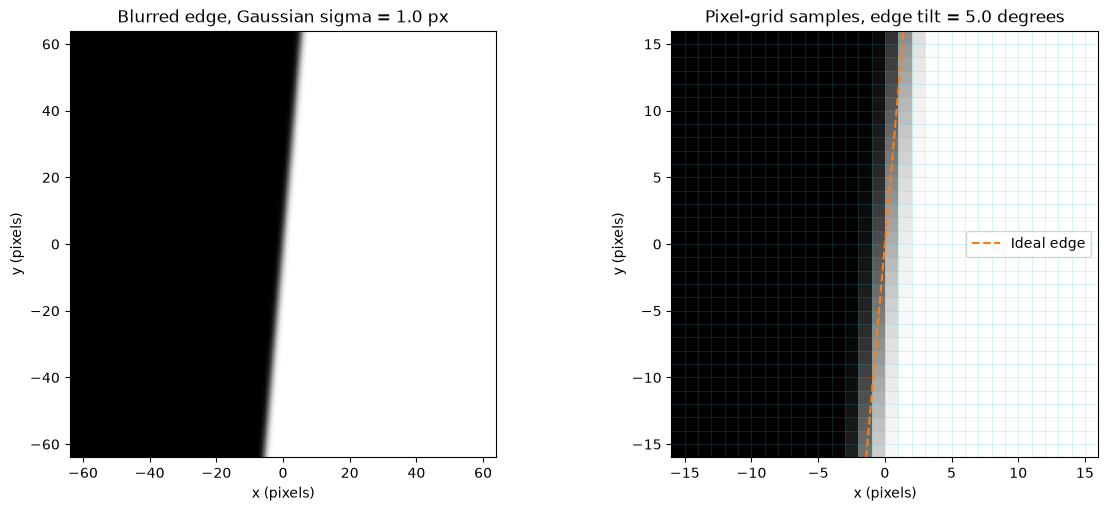

In [60]:
imageSize = 128
supersampling = 9
edgeAngleDeg = 5.0
psfSigmaPx = 1.0

highResSize = imageSize * supersampling
sampleCoordinates = (np.arange(highResSize) + 0.5) / supersampling - imageSize / 2
xHighRes, yHighRes = np.meshgrid(sampleCoordinates, sampleCoordinates)

edgeAngleRad = np.deg2rad(edgeAngleDeg)
signedDistance = (
    xHighRes * np.cos(edgeAngleRad)
    - yHighRes * np.sin(edgeAngleRad)
    )
sharpEdge = (signedDistance >= 0).astype(np.float32)
blurredHighRes = cv2.GaussianBlur(
    sharpEdge,
    (0, 0),
    sigmaX=psfSigmaPx * supersampling,
    sigmaY=psfSigmaPx * supersampling,
    borderType=cv2.BORDER_REPLICATE,
 )

sampleOffset = (supersampling - 1) // 2
sampledEdge = blurredHighRes[
    sampleOffset::supersampling, sampleOffset::supersampling
 ]

imageExtent = (
    -imageSize / 2,
    imageSize / 2,
    -imageSize / 2,
    imageSize / 2,
 )
figure, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
axes[0].imshow(
    blurredHighRes,
    extent=imageExtent,
    origin="lower",
    cmap="gray",
    vmin=0,
    vmax=1,
    interpolation="nearest",
 )
axes[0].set_title(f"Blurred edge, Gaussian sigma = {psfSigmaPx:.1f} px")
axes[0].set_xlabel("x (pixels)")
axes[0].set_ylabel("y (pixels)")

axes[1].imshow(
    sampledEdge,
    extent=imageExtent,
    origin="lower",
    cmap="gray",
    vmin=0,
    vmax=1,
    interpolation="nearest",
 )
zoomRadius = 16
axes[1].set_xlim(-zoomRadius, zoomRadius)
axes[1].set_ylim(-zoomRadius, zoomRadius)
gridBoundaries = np.arange(-zoomRadius, zoomRadius + 1)
for gridCoordinate in gridBoundaries:
    axes[1].axvline(gridCoordinate, color="tab:cyan", alpha=0.2, linewidth=0.6)
    axes[1].axhline(gridCoordinate, color="tab:cyan", alpha=0.2, linewidth=0.6)

edgeY = np.linspace(-zoomRadius, zoomRadius, 100)
edgeX = np.tan(edgeAngleRad) * edgeY
axes[1].plot(edgeX, edgeY, color="tab:orange", linestyle="--", label="Ideal edge")
axes[1].set_title(f"Pixel-grid samples, edge tilt = {edgeAngleDeg:.1f} degrees")
axes[1].set_xlabel("x (pixels)")
axes[1].set_ylabel("y (pixels)")
axes[1].legend()

plt.savefig('images/d9.png')
plt.show()

In [59]:
def measure_slanted_edge_mtf(
    image,
    roi,
    sample_spacing=1.0,
    oversampling=4,
):
    """Measure slanted-edge MTF from a 2D image and an edge-containing ROI.

    roi is (x, y, width, height) in input-image sample coordinates. Frequencies
    are returned in inverse units of sample_spacing.
    """
    imageArray = np.asarray(image)
    if imageArray.ndim != 2 or imageArray.size == 0:
        raise ValueError("image must be a non-empty 2D intensity array.")
    if not np.issubdtype(imageArray.dtype, np.number):
        raise TypeError("image must contain numeric intensity values.")
    if not np.isfinite(imageArray).all():
        raise ValueError("image must contain only finite intensity values.")

    if not isinstance(roi, (tuple, list)) or len(roi) != 4:
        raise ValueError("roi must be (x, y, width, height).")
    if any(
        not isinstance(coordinate, (int, np.integer))
        or isinstance(coordinate, (bool, np.bool_))
        for coordinate in roi
    ):
        raise TypeError("ROI coordinates must be integers.")

    roiX, roiY, roiWidth, roiHeight = map(int, roi)
    if roiX < 0 or roiY < 0 or roiWidth < 3 or roiHeight < 3:
        raise ValueError("ROI origin must be non-negative and size at least 3 by 3.")
    if (
        roiX + roiWidth > imageArray.shape[1]
        or roiY + roiHeight > imageArray.shape[0]
    ):
        raise ValueError("ROI must lie entirely inside the image.")

    if (
        isinstance(sample_spacing, (bool, np.bool_))
        or not isinstance(sample_spacing, (int, float, np.integer, np.floating))
    ):
        raise TypeError("sample_spacing must be a numeric scalar.")
    if not np.isfinite(sample_spacing) or sample_spacing <= 0:
        raise ValueError("sample_spacing must be finite and positive.")
    if (
        not isinstance(oversampling, (int, np.integer))
        or isinstance(oversampling, (bool, np.bool_))
        or oversampling < 1
    ):
        raise ValueError("oversampling must be a positive integer.")

    roiImage = imageArray[
        roiY : roiY + roiHeight, roiX : roiX + roiWidth
    ].astype(np.float64)
    if np.ptp(roiImage) == 0:
        raise ValueError("ROI has no intensity contrast; choose a crop containing an edge.")

    # Locate the half-contrast edge in each row to get subpixel edge coordinates.
    plateauWidth = max(1, roiWidth // 5)
    edgeRows = np.arange(roiY, roiY + roiHeight, dtype=np.float64)
    edgeColumns = np.empty(roiHeight, dtype=np.float64)
    for rowIndex, rowValues in enumerate(roiImage):
        darkLevel = float(np.median(rowValues[:plateauWidth]))
        lightLevel = float(np.median(rowValues[-plateauWidth:]))
        if lightLevel <= darkLevel:
            raise ValueError(
                f"ROI row {roiY + rowIndex} does not transition dark-to-light left-to-right."
            )

        threshold = (darkLevel + lightLevel) / 2
        crossingIndices = np.flatnonzero(
            (rowValues[:-1] < threshold)
            & (rowValues[1:] >= threshold)
        )
        if crossingIndices.size == 0:
            raise ValueError(
                f"No dark-to-light threshold crossing found in ROI row {roiY + rowIndex}."
            )

        crossingGradients = (
            rowValues[crossingIndices + 1] - rowValues[crossingIndices]
        )
        crossingIndex = crossingIndices[np.argmax(crossingGradients)]
        firstValue = rowValues[crossingIndex]
        secondValue = rowValues[crossingIndex + 1]
        crossingFraction = (threshold - firstValue) / (secondValue - firstValue)
        edgeColumns[rowIndex] = roiX + crossingIndex + crossingFraction

    # Fit x as a function of y because the edge is nearly vertical.
    edgeSlope, edgeIntercept = np.polyfit(edgeRows, edgeColumns, 1)
    edgeAngleDeg = float(np.rad2deg(np.arctan(edgeSlope)))
    if abs(edgeSlope) >= 1:
        raise ValueError("Edge must be closer to vertical than horizontal.")

    # Signed perpendicular distances align samples from all rows into one edge profile.
    pixelColumns = np.arange(roiX, roiX + roiWidth, dtype=np.float64)
    pixelRows = np.arange(roiY, roiY + roiHeight, dtype=np.float64)
    xCoordinates, yCoordinates = np.meshgrid(pixelColumns, pixelRows)
    pixelDistances = (
        xCoordinates - edgeSlope * yCoordinates - edgeIntercept
    ) / np.sqrt(1 + edgeSlope**2)
    pixelDistances *= sample_spacing

    # Bin at a fraction of one sample spacing to form the oversampled ESF.
    binWidth = sample_spacing / oversampling
    distanceMinimum = float(np.min(pixelDistances))
    distanceMaximum = float(np.max(pixelDistances))
    binCount = int(np.ceil((distanceMaximum - distanceMinimum) / binWidth)) + 1
    binIndices = np.floor(
        (pixelDistances - distanceMinimum) / binWidth
    ).astype(np.int64)
    intensitySums = np.bincount(
        binIndices.ravel(), weights=roiImage.ravel(), minlength=binCount
    )
    sampleCounts = np.bincount(binIndices.ravel(), minlength=binCount)
    binCenters = distanceMinimum + (np.arange(binCount) + 0.5) * binWidth
    populatedBins = sampleCounts > 0
    if np.count_nonzero(populatedBins) < 3:
        raise ValueError("ROI does not provide enough samples to build an ESF.")
    esf = np.interp(
        binCenters,
        binCenters[populatedBins],
        intensitySums[populatedBins] / sampleCounts[populatedBins],
    )

    # Normalize the dark and light tails so the MTF is independent of image contrast.
    plateauBinCount = max(1, binCount // 10)
    darkLevel = float(np.median(esf[:plateauBinCount]))
    lightLevel = float(np.median(esf[-plateauBinCount:]))
    if lightLevel <= darkLevel:
        raise ValueError("Binned ESF must transition from dark to light.")
    esf = (esf - darkLevel) / (lightLevel - darkLevel)

    # Differentiate the ESF; windowing its ends reduces finite-ROI FFT artifacts.
    lsf = np.gradient(esf, binWidth)
    windowedLsf = lsf * np.hanning(lsf.size)

    # Zero-pad the transform for a smoother frequency grid, then normalize at DC.
    fftLength = 1 << int(np.ceil(np.log2(4 * windowedLsf.size)))
    spectrum = np.abs(np.fft.rfft(windowedLsf, n=fftLength))
    if spectrum[0] <= np.finfo(np.float64).eps:
        raise ValueError("LSF has no measurable DC response.")
    allFrequencies = np.fft.rfftfreq(fftLength, d=binWidth)
    allMtf = spectrum / spectrum[0]

    # Restrict reported frequencies to the input image's Nyquist limit.
    nyquistFrequency = 0.5 / sample_spacing
    belowNyquist = allFrequencies <= nyquistFrequency
    frequency = allFrequencies[belowNyquist]
    mtf = allMtf[belowNyquist]

    # Interpolate the first downward 0.5 crossing; NaN means it is not resolved.
    crossingIndices = np.flatnonzero((mtf[:-1] >= 0.5) & (mtf[1:] < 0.5))
    mtf50 = np.nan
    if crossingIndices.size:
        crossingIndex = crossingIndices[0]
        frequencyFraction = (
            (0.5 - mtf[crossingIndex])
            / (mtf[crossingIndex + 1] - mtf[crossingIndex])
        )
        mtf50 = frequency[crossingIndex] + frequencyFraction * (
            frequency[crossingIndex + 1] - frequency[crossingIndex]
        )

    return {
        "roiImage": roiImage,
        "edgeRows": edgeRows,
        "edgeColumns": edgeColumns,
        "edgeAngleDeg": edgeAngleDeg,
        "esfDistance": binCenters,
        "esf": esf,
        "lsf": lsf,
        "frequency": frequency,
        "mtf": mtf,
        "nyquistFrequency": nyquistFrequency,
        "mtf50": mtf50,
    }

ROI shape: (96, 96)
Detected row crossings: 96
Measured edge angle: 5.00 degrees
Measured MTF50: 0.1013 cycles/um
Gaussian reference MTF50: 0.1026 cycles/um


ROI shape: (96, 96)
Detected row crossings: 96
Measured edge angle: 5.00 degrees
Measured MTF50: 0.1013 cycles/um
Gaussian reference MTF50: 0.1026 cycles/um


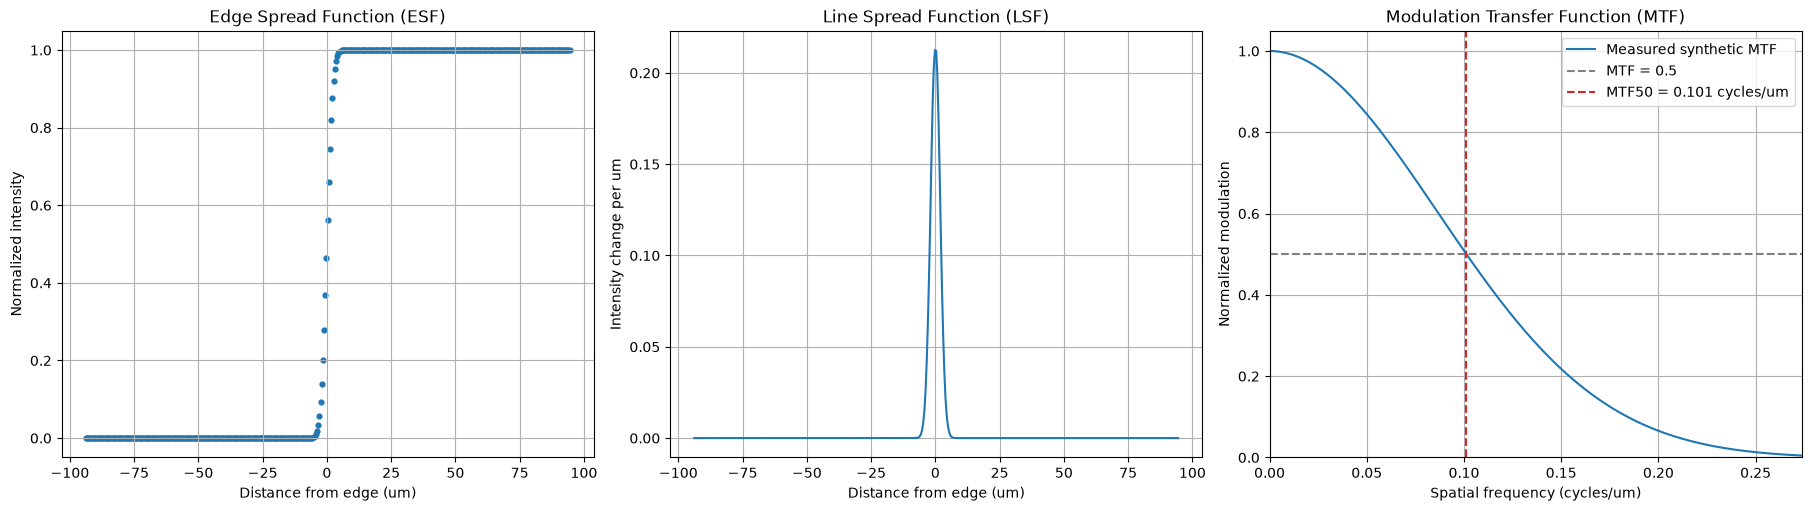

In [77]:
syntheticEdgeMeasurement = measure_slanted_edge_mtf(
    sampledEdge,
    roi=(16, 16, 96, 96),
    sample_spacing=1.0,
    oversampling=4,
)
edgeLineFit = np.polyfit(
    syntheticEdgeMeasurement["edgeRows"],
    syntheticEdgeMeasurement["edgeColumns"],
    1,
)
measuredEdgeAngleDeg = np.rad2deg(np.arctan(edgeLineFit[0]))
expectedMtf50 = np.sqrt(np.log(2) / 2) / (np.pi * psfSigmaPx)
print(f"ROI shape: {syntheticEdgeMeasurement['roiImage'].shape}")
print(f"Detected row crossings: {len(syntheticEdgeMeasurement['edgeRows'])}")
print(f"Measured edge angle: {measuredEdgeAngleDeg:.2f} degrees")
print(
    f"Measured MTF50: {syntheticEdgeMeasurement['mtf50']:.4f} cycles/pixel"
)
print(f"Gaussian reference MTF50: {expectedMtf50:.4f} cycles/pixel")
assert 4.5 <= measuredEdgeAngleDeg <= 5.5
assert np.isfinite(syntheticEdgeMeasurement["mtf50"])
assert abs(syntheticEdgeMeasurement["mtf50"] - expectedMtf50) < 0.03

figure, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
axes[0].scatter(
    syntheticEdgeMeasurement["esfDistance"],
    syntheticEdgeMeasurement["esf"],
    s=12,
)
axes[0].set_title("Edge Spread Function (ESF)")
axes[0].set_xlabel("Distance from edge (pixels)")
axes[0].set_ylabel("Normalized intensity")
axes[0].grid(True)

axes[1].plot(
    syntheticEdgeMeasurement["esfDistance"],
    syntheticEdgeMeasurement["lsf"],
)
axes[1].set_title("Line Spread Function (LSF)")
axes[1].set_xlabel("Distance from edge (pixels)")
axes[1].set_ylabel("Intensity change per pixel")
axes[1].grid(True)

axes[2].plot(
    syntheticEdgeMeasurement["frequency"],
    syntheticEdgeMeasurement["mtf"],
    label="Measured synthetic MTF",
)
axes[2].axhline(0.5, color="gray", linestyle="--", label="MTF = 0.5")
axes[2].axvline(
    syntheticEdgeMeasurement["mtf50"],
    color="tab:red",
    linestyle="--",
    label=f"MTF50 = {syntheticEdgeMeasurement['mtf50']:.3f} cycles/pixel",
)
axes[2].set_title("Modulation Transfer Function (MTF)")
axes[2].set_xlabel("Spatial frequency (cycles/pixel)")
axes[2].set_ylabel("Normalized modulation")
axes[2].set_xlim(0, syntheticEdgeMeasurement["nyquistFrequency"])
axes[2].set_ylim(0, 1.05)
axes[2].grid(True)
axes[2].legend()
plt.savefig('images/d10.png')
plt.show()

In [102]:
error = 100 * (0.1874-0.1850)/(0.1874)
print(error)

1.280683030949847


## Deliverable 12 - 16

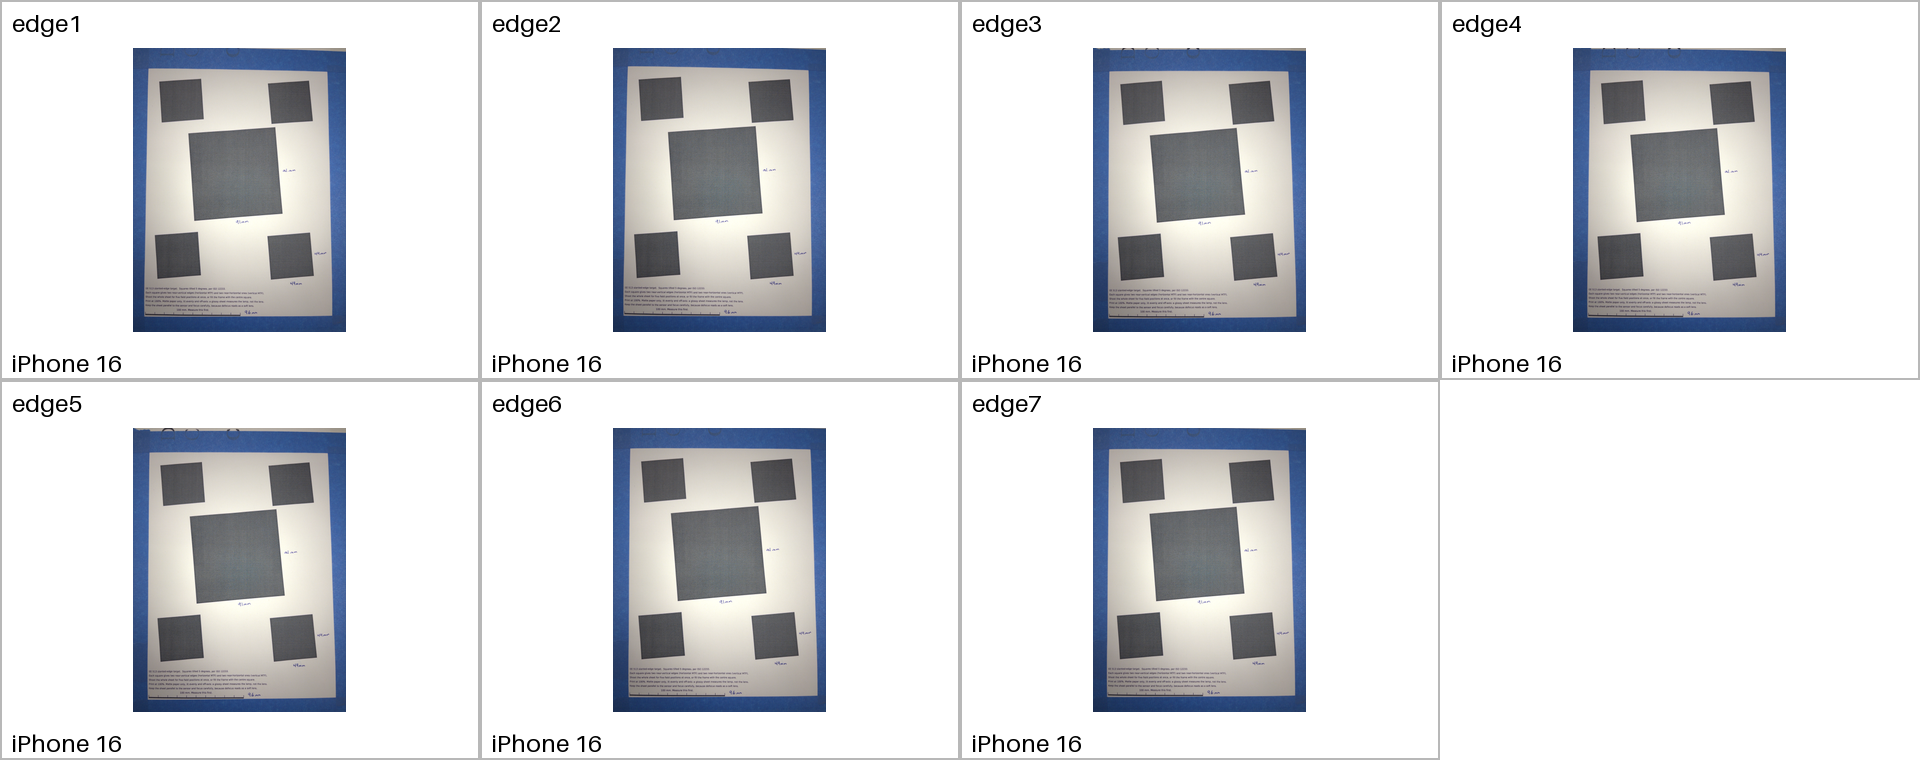

In [67]:
from importlib import reload
from pathlib import Path

import utils

reload(utils)
from utils import create_contact_sheet

imagePaths = sorted(
    Path("images").glob("edge*.DNG"),
    key=lambda imagePath: int(imagePath.stem[4:]),
)

sheet = create_contact_sheet(
    imagePaths,
    columns=4,
    outputPath="images/d12.png",
)
display(sheet)  # Notebook only

Processing image 0: images\edge1.DNG


Processing image 0: images\edge1.DNG


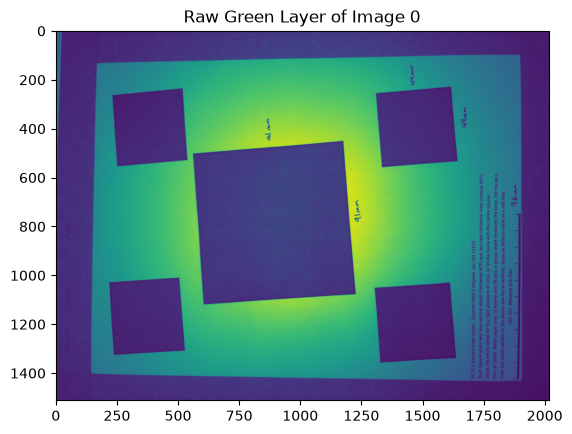

Processing image 0: images\edge1.DNG


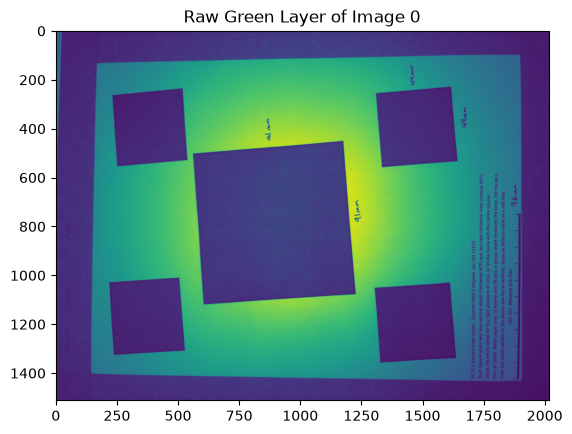

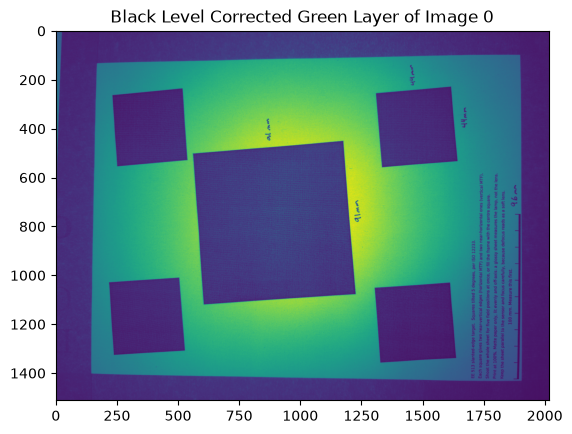

Processing image 0: images\edge1.DNG


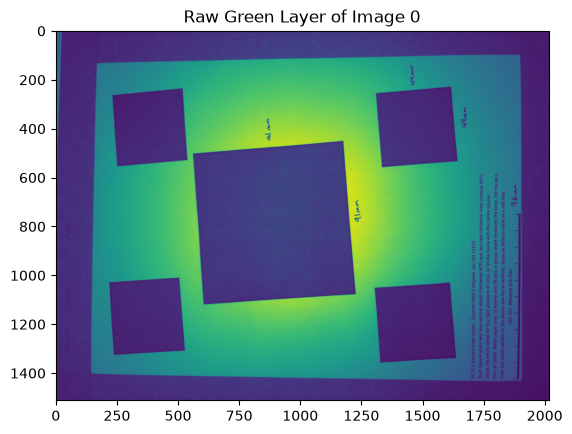

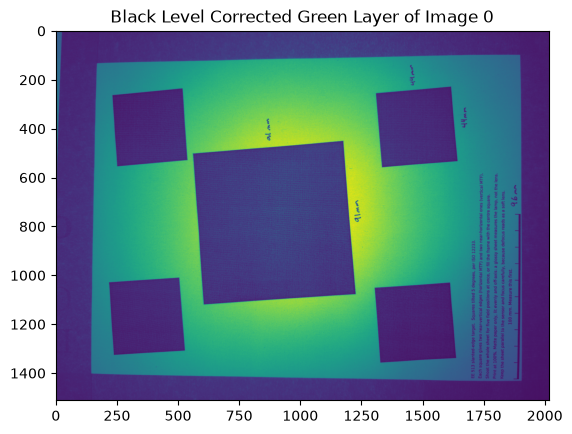

edge1.DNG: black level = 528.0, shape = (1512, 2016)
Processing image 1: images\edge2.DNG
edge2.DNG: black level = 528.0, shape = (1512, 2016)
Processing image 2: images\edge3.DNG
edge3.DNG: black level = 528.0, shape = (1512, 2016)
Processing image 3: images\edge4.DNG
edge4.DNG: black level = 528.0, shape = (1512, 2016)
Processing image 4: images\edge5.DNG
edge5.DNG: black level = 528.0, shape = (1512, 2016)
Processing image 5: images\edge6.DNG
edge6.DNG: black level = 528.0, shape = (1512, 2016)
Processing image 6: images\edge7.DNG
edge7.DNG: black level = 528.0, shape = (1512, 2016)


In [69]:
greenPlanes = {}
for index, path in enumerate(imagePaths):
    
    print(f"Processing image {index}: {path}")
    with rawpy.imread(str(path)) as raw:
        channel = int(raw.raw_colors_visible[0, 1])
        assert raw.color_desc[channel:channel + 1] == b'G'
        blackLevel = float(raw.black_level_per_channel[channel])
        greenLayer = raw.raw_image_visible[0::2, 1::2].astype(np.float32)
        greenLayer -= blackLevel
        if index < 1:
            plt.imshow(greenLayer, vmin=0, vmax=np.max(greenLayer))
            plt.title(f"Raw Green Layer of Image {index}")
            plt.show()
            plt.imshow(greenLayer, vmin=0, vmax=np.max(greenLayer))
            plt.title(f"Black Level Corrected Green Layer of Image {index}")
            plt.savefig('images/d14.png')
            plt.show()
    
    greenPlanes[path.name] = greenLayer
    print(f'{path.name}: black level = {blackLevel}, shape = {greenLayer.shape}')

In [81]:
from importlib import reload
import utils
reload(utils)
from utils import select_largest_square_edge
mtf50 = {}
measuredModulationAtNyquist = {}

squareSelections = {}
for imageName, greenPlane in greenPlanes.items():
    displayMin, displayMax = np.percentile(greenPlane, (1, 99))
    try:
        selection = select_largest_square_edge(greenPlane)
    except ValueError as error:
        print(f"{imageName}: selection failed: {error}")
    else:
        squareSelections[imageName] = selection
        corners = selection["squareCorners"]
        outline = np.vstack((corners, corners[0]))
        left, top, width, height = selection["roi"]
        crop = greenPlane[top:top + height, left:left + width]
        print(f"{imageName}: ROI = {selection['roi']}, angle = {selection['edgeAngleDeg']:.2f} degrees \nImage size: {crop.shape}")
        syntheticEdgeMeasurement = measure_slanted_edge_mtf(
            greenPlane,
            roi=selection["roi"],
            sample_spacing=2 * p,
            oversampling=4,
        )
        mtf50[imageName] = syntheticEdgeMeasurement["mtf50"]
        measuredModulationAtNyquist[imageName] = float(
            np.interp(
                nF,
                syntheticEdgeMeasurement["frequency"],
                syntheticEdgeMeasurement["mtf"],
            )
        )
print(mtf50)
print(f"\nMean: {np.mean(list(mtf50.values()))}")
print(f"Standard deviation: {np.std(list(mtf50.values()))}")

edge1.DNG: ROI = (1181, 607, 39, 313), angle = 4.67 degrees 
Image size: (313, 39)
edge2.DNG: ROI = (1178, 608, 37, 306), angle = 4.46 degrees 
Image size: (306, 37)
edge3.DNG: ROI = (1189, 589, 41, 296), angle = 5.22 degrees 
Image size: (296, 41)
edge4.DNG: ROI = (1190, 591, 38, 308), angle = 4.77 degrees 
Image size: (308, 38)
edge5.DNG: ROI = (1195, 591, 42, 296), angle = 5.31 degrees 
Image size: (296, 42)
edge6.DNG: ROI = (1179, 580, 41, 303), angle = 5.01 degrees 
Image size: (303, 41)
edge7.DNG: ROI = (1180, 594, 41, 296), angle = 5.03 degrees 
Image size: (296, 41)
{'edge1.DNG': np.float64(0.07429060234479462), 'edge2.DNG': np.float64(0.08121342302787242), 'edge3.DNG': np.float64(0.07772495246916873), 'edge4.DNG': np.float64(0.07916366943610202), 'edge5.DNG': np.float64(0.0751072781043145), 'edge6.DNG': np.float64(0.07855261493341502), 'edge7.DNG': np.float64(0.07935534303450113)}

Mean: 0.07791541190716691
Standard deviation: 0.002267017807437675


In [84]:
meanMtf50CyclesPerUm = np.mean(list(mtf50.values()))
meanMtf50CyclesPerGreenPixel = meanMtf50CyclesPerUm * (2 * p)
predictedModulationAtNyquist = float(mtfd(nF, v_c) * mtfp(nF, p))
meanMeasuredModulationAtNyquist = np.mean(
    list(measuredModulationAtNyquist.values())
)
print(
    f"Mean MTF50: {meanMtf50CyclesPerUm:.4f} cycles/um "
    f"({meanMtf50CyclesPerGreenPixel:.4f} cycles/green-plane pixel)"
)
print(
    f"Predicted modulation at green-plane Nyquist "
    f"({nF:.4f} cycles/um): {predictedModulationAtNyquist:.4f}"
)
print(
    f"Mean measured modulation at green-plane Nyquist "
    f"({nF:.4f} cycles/um): {meanMeasuredModulationAtNyquist:.4f}"
)

Mean MTF50: 0.0779 cycles/um (0.2847 cycles/green-plane pixel)
Predicted modulation at green-plane Nyquist (0.1368 cycles/um): 0.7626
Mean measured modulation at green-plane Nyquist (0.1368 cycles/um): 0.2104
